# Supplementary Figure S6. FastRNA base-pair scores and relationships with structural-quality measures

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr

def _root() -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data").is_dir() and (base / "notebooks").is_dir():
            return base
    raise RuntimeError("run this from inside the analysis repo")

ROOT = _root()
data_file = lambda rel: ROOT / "data" / rel
_json = lambda rel: json.loads(data_file(rel).read_text())

def save(fig, rel):
    path = ROOT / rel
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path)
    return path

plt.rcParams.update({
    "figure.dpi": 130, "savefig.dpi": 300, "savefig.bbox": "tight",
    "savefig.pad_inches": 0.08,
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "Helvetica", "DejaVu Sans"],
    "font.size": 8.5, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.8, "xtick.major.width": 0.8, "ytick.major.width": 0.8,
    "xtick.direction": "out", "ytick.direction": "out",
    "axes.grid": False, "legend.frameon": False,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})
BLUE, ORANGE, RED, GREY = "#4C72B0", "#DD8452", "#C44E52", "0.55"
POINT_FACE, POINT_EDGE, FIT = "#C9C9C9", "0.15", "#111111"

def finish(ax):
    for side in ("top", "right", "bottom", "left"):
        ax.spines[side].set_visible(True)
        ax.spines[side].set_linewidth(0.8)
    ax.grid(False)
    ax.tick_params(direction="out", width=0.8, length=3.5)
    return ax

def letter(fig, ax, s, dx=-0.030, dy=0.018):
    box = ax.get_position()
    fig.text(box.x0 + dx, box.y1 + dy, s, fontsize=13, fontweight="bold",
             ha="left", va="bottom")

def _resolution(m):
    if not isinstance(m, dict):
        return None
    return (m.get("EM Diffraction Resolution (\u00c5)") or m.get("Refinement_resolution")
            or m.get("EM Resolution (\u00c5)"))

def structure_scores() -> pd.DataFrame:
    sc = _json("reference/scores/scores_all_uniques.json")["scores"]
    md = _json("reference/metadata/metadata_cache.json")
    vm, nt = md["validation_metrics"], md["nucleotide_counts"]
    rows = []
    for pdb, info in sc.items():
        m = vm.get(pdb) if isinstance(vm.get(pdb), dict) else {}
        rows.append({
            "pdb": pdb,
            "pairs_score": info.get("pairs_score"),
            "backbone_suiteness": info.get("backbone_suiteness"),
            "n_pairs": info.get("n_pairs", 0),
            "n_residues_scored": info.get("n_residues_scored", 0),
            "method": m.get("Experimental_method"),
            "resolution": _resolution(m),
            "clashscore": m.get("clashscore"),
            "n_nucleotides": nt.get(pdb),
        })
    return pd.DataFrame(rows)

def pair_scores() -> pd.DataFrame:
    return pd.read_json(data_file("reference/scores/pair_scores_uniques_parse.jsonl"), lines=True)

STRUCT = structure_scores()
_N_SCORED = pair_scores().dropna(subset=["score"]).groupby("pdb_id").size()
STRUCT["n_scored"] = STRUCT["pdb"].map(_N_SCORED).fillna(0).astype(int)
print(f"{len(STRUCT):,} scored structures | "
      f"{STRUCT.resolution.notna().sum():,} with resolution | "
      f"{STRUCT.clashscore.notna().sum():,} with clashscore")

AXIS_LABEL_PT = 8.5


def enlarge_axis_labels(fig, text_pt=7.0, axis_pt=AXIS_LABEL_PT):
    for ax in fig.axes:
        for lab in (ax.xaxis.label, ax.yaxis.label):
            if lab.get_text().strip():
                lab.set_fontsize(lab.get_fontsize() * axis_pt / text_pt)


2,697 scored structures | 2,697 with resolution | 2,671 with clashscore


## Shared scatter

In [2]:
def scatter_vs(ax, xcol, xlabel, *, min_pairs=5, need_backbone=False, clip_q=None,
               stat_side="right", show_ylabel=True, compact=False):
    d = STRUCT.dropna(subset=["pairs_score", xcol])
    d = d[d["n_scored"] >= min_pairs]
    if need_backbone:
        d = d[d["n_residues_scored"] > 0]
    if xcol == "resolution":
        d = d[d[xcol] > 0]
    ax.scatter(d[xcol], d["pairs_score"], s=6 if compact else 13, facecolor=BLUE,
               edgecolor=POINT_EDGE, linewidths=0.35, alpha=0.55)
    fit = d
    slope, intercept = np.polyfit(fit[xcol], fit["pairs_score"], 1)
    xs = np.linspace(fit[xcol].min(), fit[xcol].max(), 100)
    r, _ = pearsonr(fit[xcol], fit["pairs_score"])
    ax.plot(xs, slope * xs + intercept, color=FIT, lw=1.2, zorder=3)
    x, ha = (0.97, "right") if stat_side == "right" else (0.03, "left")
    ax.text(x, 0.06, f"n = {len(d):,}\nR\u00b2 = {r**2:.3f}", transform=ax.transAxes,
            ha=ha, va="bottom", fontsize=7 if compact else 8, color="0.25")
    if clip_q is not None:
        ax.set_xlim(0, d[xcol].quantile(clip_q))
    ax.set_ylim(top=101)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Base-pair score" if show_ylabel else "")
    finish(ax)
    return len(d)


## Panel A
Base-pair quality score versus experimental resolution

1,865 structures


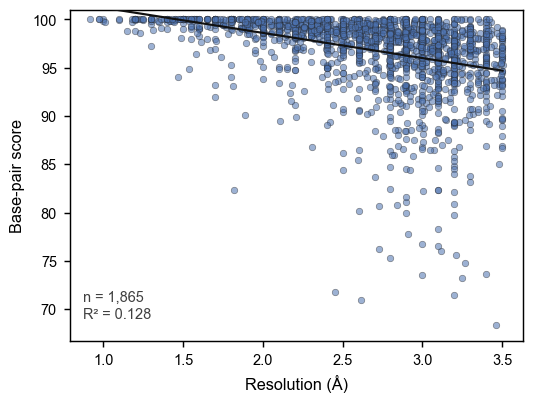

In [3]:
def draw_a(ax, **kw):
    return scatter_vs(ax, "resolution", "Resolution (\u00c5)", stat_side="left", **kw)

fig, ax = plt.subplots(figsize=(4.2, 3.2))
print(f"{draw_a(ax):,} structures")
fig.tight_layout()
save(fig, "figures/supplemental/figS6_A_score_vs_resolution.png")
plt.show()


## Panel B
Base-pair quality score versus clashscore

1,843 structures


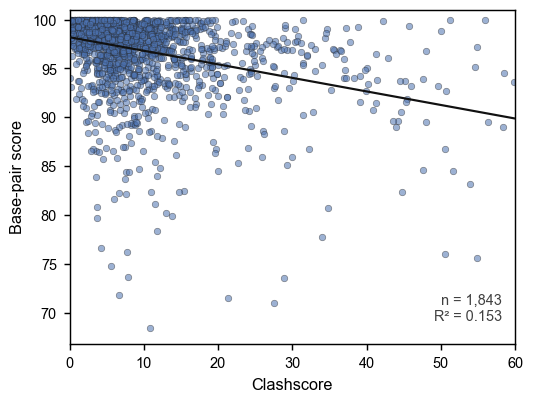

In [4]:
def draw_b(ax, **kw):
    n = scatter_vs(ax, "clashscore", "Clashscore", **kw)
    ax.set_xlim(0, 60)
    return n

fig, ax = plt.subplots(figsize=(4.2, 3.2))
print(f"{draw_b(ax):,} structures")
fig.tight_layout()
save(fig, "figures/supplemental/figS6_B_score_vs_clashscore.png")
plt.show()


## Panel C
Base-pair quality score versus backbone suiteness

1,864 structures


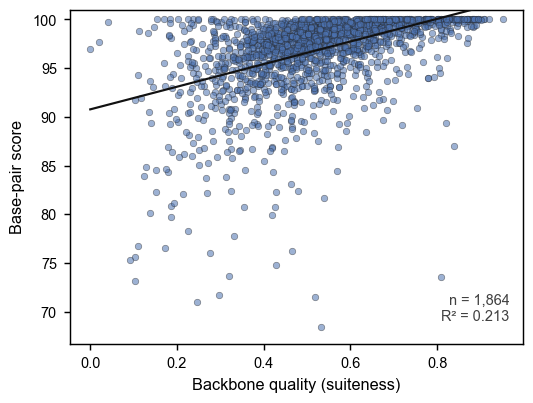

In [5]:
def draw_c(ax, **kw):
    label = "Backbone suiteness" if kw.get("compact") else "Backbone quality (suiteness)"
    return scatter_vs(ax, "backbone_suiteness", label,
                             need_backbone=True, **kw)

fig, ax = plt.subplots(figsize=(4.2, 3.2))
print(f"{draw_c(ax):,} structures")
fig.tight_layout()
save(fig, "figures/supplemental/figS6_C_score_vs_backbone.png")
plt.show()


## Panel D
Base-pair quality score versus RNA length

1,865 structures


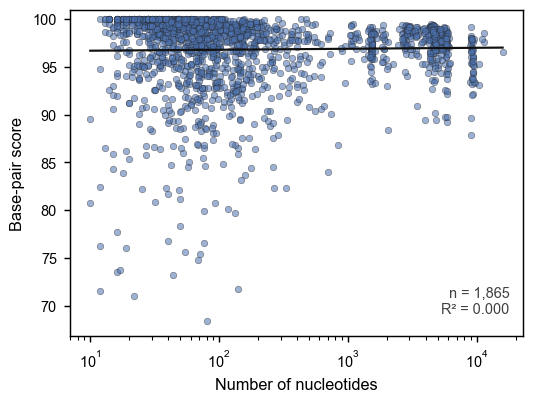

In [6]:
def draw_d(ax, show_ylabel=True, compact=False):
    d = STRUCT.dropna(subset=["n_nucleotides", "pairs_score"])
    d = d[(d["n_scored"] >= 5) & (d["n_nucleotides"] > 0)]
    ax.scatter(d["n_nucleotides"], d["pairs_score"], s=6 if compact else 13, facecolor=BLUE,
               edgecolor=POINT_EDGE, linewidths=0.35, alpha=0.55)
    logn = np.log10(d["n_nucleotides"].to_numpy(float))
    slope, intercept = np.polyfit(logn, d["pairs_score"], 1)
    xs = np.logspace(logn.min(), logn.max(), 100)
    r, _ = pearsonr(logn, d["pairs_score"])
    ax.plot(xs, slope * np.log10(xs) + intercept, color=FIT, lw=1.2, zorder=3)
    ax.text(0.97, 0.06, f"n = {len(d):,}\nR\u00b2 = {r**2:.3f}", transform=ax.transAxes,
            ha="right", va="bottom", fontsize=7 if compact else 8, color="0.25")
    ax.set_xscale("log")
    ax.set_ylim(top=101)
    ax.set_xlabel("Number of nucleotides")
    ax.set_ylabel("Base-pair score" if show_ylabel else "")
    finish(ax)
    return len(d)

fig, ax = plt.subplots(figsize=(4.2, 3.2))
print(f"{draw_d(ax):,} structures")
fig.tight_layout()
save(fig, "figures/supplemental/figS6_D_score_vs_length.png")
plt.show()

## Combined figure


saved 7.16 x 2.35 in; at 6.73 in wide the smallest text prints at 7.02 pt, height 2.21 in


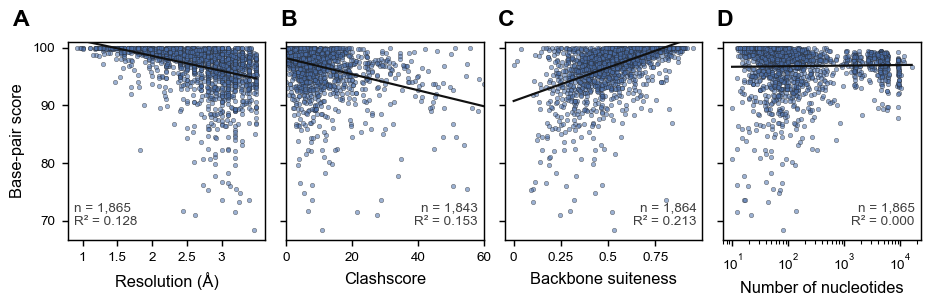

In [7]:
PANEL_IN = 1.52
GAP = 0.16
LEFT, TOP = 0.55, 0.32
COL_X = [LEFT + i * (PANEL_IN + GAP) for i in range(4)]
FIG_W = COL_X[-1] + PANEL_IN + 0.1
FIG_H = TOP + PANEL_IN + 0.52
fig = plt.figure(figsize=(FIG_W, FIG_H))
inch = lambda x, y, w, h: [x / FIG_W, 1 - (y + h) / FIG_H, w / FIG_W, h / FIG_H]
axes = [fig.add_axes(inch(x, TOP, PANEL_IN, PANEL_IN)) for x in COL_X]

draw_a(axes[0], compact=True)
draw_b(axes[1], show_ylabel=False, compact=True)
draw_c(axes[2], show_ylabel=False, compact=True)
draw_d(axes[3], show_ylabel=False, compact=True)
y_lo = min(ax.get_ylim()[0] for ax in axes)
for ax in axes:
    ax.set_ylim(y_lo, 101)
for ax in axes[1:]:
    ax.tick_params(labelleft=False)
for ax, ticks in ((axes[0], [1, 1.5, 2, 2.5, 3]), (axes[1], [0, 20, 40, 60]),
                  (axes[2], [0, 0.25, 0.5, 0.75])):
    lo, hi = ax.get_xlim()
    ax.set_xticks(ticks)
    ax.set_xticklabels([f"{t:g}" for t in ticks])
    ax.set_xlim(lo, hi)

TEXT_PT, LETTER_PT = 7, 12


def set_uniform_text(fig, size=TEXT_PT):
    import matplotlib.text as mtext
    for t in fig.findobj(mtext.Text):
        if t.get_fontsize() >= LETTER_PT and t.get_fontweight() in ("bold", 700):
            continue
        t.set_fontsize(size)


set_uniform_text(fig)
enlarge_axis_labels(fig)
inv = fig.transFigure.inverted()
fig.canvas.draw()
renderer = fig.canvas.get_renderer()
for ax, s in zip(axes, "ABCD"):
    x = ax.get_tightbbox(renderer).transformed(inv).x0
    fig.text(x, ax.get_position().y1 + 0.09 / FIG_H, s, fontsize=LETTER_PT,
             fontweight="bold", ha="left", va="bottom")

def _ensure_print_pt(fig, min_pt=7.0, page_in=6.73, pad=0.08):
    import matplotlib.text as mtext
    texts = [t for t in fig.findobj(mtext.Text) if t.get_visible() and t.get_text().strip()]
    for _ in range(8):
        fig.canvas.draw()
        bb = fig.get_tightbbox(fig.canvas.get_renderer())
        shrink = max(1.0, (bb.width + 2 * pad) / page_in)
        smallest = min(t.get_fontsize() for t in texts) / shrink
        if smallest >= min_pt - 1e-3:
            break
        for t in texts:
            t.set_fontsize(t.get_fontsize() * min_pt / smallest * 1.005)
    print(f"saved {bb.width + 2 * pad:.2f} x {bb.height + 2 * pad:.2f} in; at {page_in} in wide "
          f"the smallest text prints at {smallest:.2f} pt, height {(bb.height + 2 * pad) / shrink:.2f} in")


_ensure_print_pt(fig)

save(fig, "figures/supplemental/figS6.png")
plt.show()